# 04 - Muscle activity and coordination

**Question.** How do the twelve lower-limb muscles organise walking, and how does that organisation
change with speed? Two levels are examined:

* **Activation profiles:** amplitude and timing of each muscle across the gait cycle;
* **Muscle synergies:** the small number of co-activation modules that reconstruct all six muscles of a leg
  (non-negative matrix factorisation), and whether those modules are shared across speeds and people.

**Data constraints.** The release provides the Delsys mean-absolute-value envelope at 16 Hz (about 18 to
28 samples per stride), not raw EMG. Profiles are therefore interpolated onto 101 points per stride from a
coarse envelope, which is adequate for timing to within a few percent of the cycle and for synergy analysis,
but not for spectral measures. Strides are segmented with IMU gait events (same trigger network as the EMG);
channels flagged as noise-dominated in notebook 01 are excluded.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from mgait import config as C, emg as M, plotting as P, stats as S

P.use_style()
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 3)
cyc = pd.read_parquet(C.CACHE / "emg_strides.parquet")
cur = dict(np.load(C.CACHE / "emg_curves.npz"))
T = pd.read_parquet(C.TABLES / "trial_features.parquet")
print(f"{len(cyc)} EMG gait cycles, {cyc.groupby(['subject', 'speed']).ngroups} trials, {cyc.subject.nunique()} participants "
      f"(event source: {cyc['event_source'].value_counts().to_dict()})")

14882 EMG gait cycles, 168 trials, 58 participants (event source: {'imu': 14401, 'fp': 481})


## 1. Activation profiles

Each participant's profile is averaged over strides and both legs, then scaled to that participant's peak
for the muscle across all three speeds, so amplitude changes between speeds are preserved while differences
in electrode impedance between people are removed.

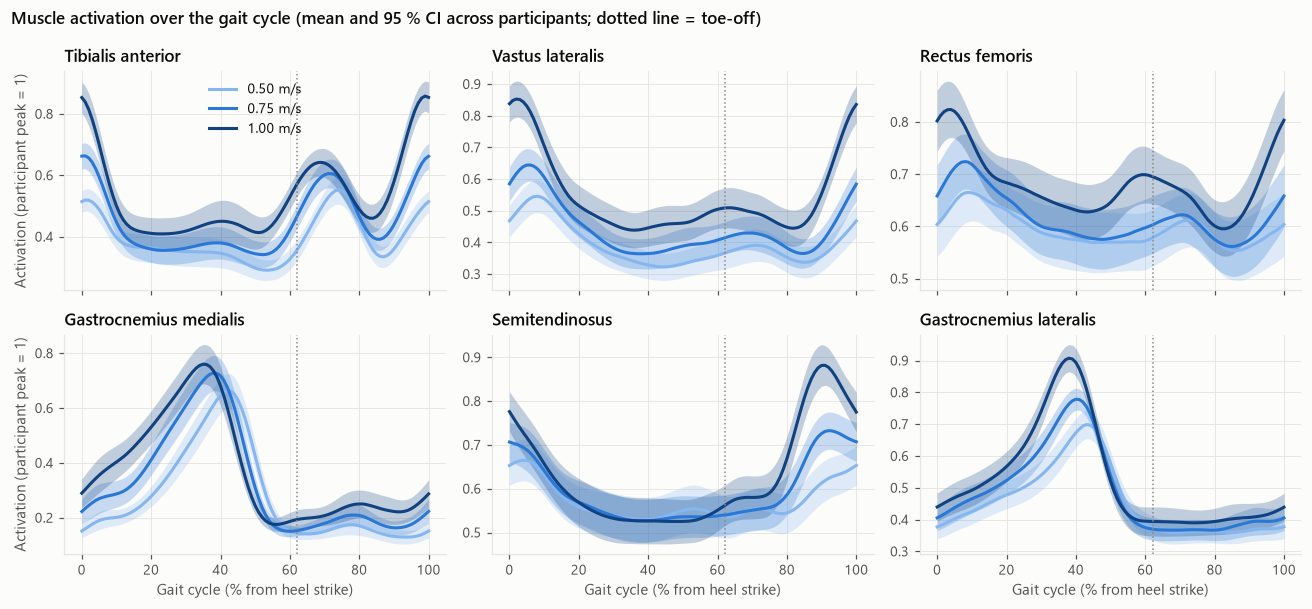

In [2]:
key = cyc["subject"] + "|" + cyc["speed"]
prof = {}
for m in C.MUSCLES:
    df = pd.DataFrame(cur[m]); df["subject"], df["speed"] = cyc["subject"].values, cyc["speed"].values
    p = df.groupby(["subject", "speed"]).mean()
    peak = p.max(axis=1).groupby(level="subject").max()
    prof[m] = p.div(peak, axis=0, level="subject")
x = np.arange(101)
fig, axes = plt.subplots(2, 3, figsize=(12, 5.6), sharex=True)
for ax, m in zip(axes.flat, C.MUSCLES):
    for s in C.SPEEDS:
        X = prof[m].xs(s, level="speed").dropna().to_numpy()
        P.band(ax, x, X.mean(0), X.std(0) / np.sqrt(len(X)) * 1.96, P.SPEED_COLORS[s], P.SPEED_LABEL[s], alpha=0.25)
    ax.set_title(C.MUSCLE_NAMES[m])
    ax.axvline(cyc["stance_pct"].median(), color=P.MUTED, ls=":", lw=1)
for ax in axes[1]:
    ax.set_xlabel("Gait cycle (% from heel strike)")
for ax in axes[:, 0]:
    ax.set_ylabel("Activation (participant peak = 1)")
axes[0, 0].legend(loc="upper center")
fig.suptitle("Muscle activation over the gait cycle (mean and 95 % CI across participants; dotted line = toe-off)",
             x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
P.save(fig, "04_emg_profiles")
plt.show()

The timing pattern is the expected one for walking, which independently confirms that the EMG and the IMU
gait events are synchronised: tibialis anterior fires at heel strike (controlling foot lowering) and again in
swing (toe clearance); the vasti and rectus femoris act in loading response; both gastrocnemius heads peak in
late stance for push-off; semitendinosus brakes the swinging leg before the next heel strike.

## 2. How activation scales with speed

,trials,amplitude change per +0.5 m/s (%),ci_lo (%),ci_hi (%),peak timing shift per +0.5 m/s (% cycle),p_amp_holm,p_timing_holm
muscle,,,,,,,
Tibialis anterior,168,40.048,35.423,44.831,11.907,2.990e-85,2.817e-02
Vastus lateralis,163,49.030,37.556,61.460,6.598,6.613e-22,2.427e-01
Rectus femoris,168,18.259,11.704,25.199,2.283,1.642e-08,5.936e-01
Gastrocnemius medialis,167,44.608,32.785,57.484,-6.955,7.015e-17,2.271e-04
Semitendinosus,168,16.775,9.821,24.170,30.775,7.413e-07,3.888e-12
Gastrocnemius lateralis,168,22.327,18.112,26.692,-4.031,9.726e-29,8.653e-03


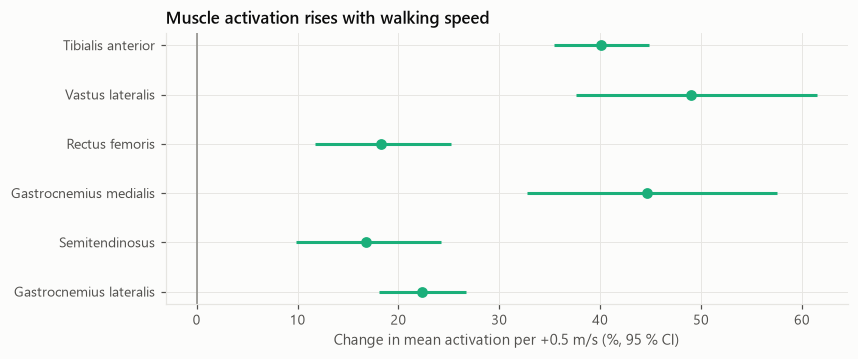

In [3]:
rows = []
for m in C.MUSCLES:
    d = T[["subject", "speed_ms", f"emg_{m}_act", f"emg_{m}_peak"]].dropna()
    r = S.mixed_model(d.rename(columns={f"emg_{m}_act": "y"}), "y ~ speed_ms")
    b, (lo, hi) = r.params["speed_ms"], r.conf_int().loc["speed_ms"]
    rt = S.mixed_model(d.rename(columns={f"emg_{m}_peak": "y"}), "y ~ speed_ms")
    rows.append({"muscle": C.MUSCLE_NAMES[m], "trials": len(d),
                 "amplitude change per +0.5 m/s (%)": 100 * (10 ** (0.5 * b) - 1),
                 "ci_lo (%)": 100 * (10 ** (0.5 * lo) - 1), "ci_hi (%)": 100 * (10 ** (0.5 * hi) - 1), "p_amp": r.pvalues["speed_ms"],
                 "peak timing shift per +0.5 m/s (% cycle)": 0.5 * rt.params["speed_ms"], "p_timing": rt.pvalues["speed_ms"]})
emg_eff = pd.DataFrame(rows)
emg_eff["p_amp_holm"] = S.holm(emg_eff["p_amp"].to_numpy())
emg_eff["p_timing_holm"] = S.holm(emg_eff["p_timing"].to_numpy())
emg_eff.to_csv(C.TABLES / "emg_speed_effects.csv", index=False)
display(emg_eff.set_index("muscle").drop(columns=["p_amp", "p_timing"]))

fig, ax = plt.subplots(figsize=(8, 3.2))
yy = np.arange(len(emg_eff))[::-1]
ax.hlines(yy, emg_eff["ci_lo (%)"], emg_eff["ci_hi (%)"], color=P.CAT[2], lw=2)
ax.scatter(emg_eff["amplitude change per +0.5 m/s (%)"], yy, color=P.CAT[2], s=50, zorder=3)
ax.axvline(0, color=P.MUTED, lw=1)
ax.set_yticks(yy, emg_eff["muscle"])
ax.set_xlabel("Change in mean activation per +0.5 m/s (%, 95 % CI)")
ax.set_title("Muscle activation rises with walking speed")
P.save(fig, "04_emg_amplitude")
plt.show()

## 3. Muscle synergies

For each trial and leg with all six muscles valid, the stride-by-stride envelopes are concatenated into a
6 x (strides x 101) matrix. Each muscle's noise floor (2nd percentile) is removed, because the envelope
never reaches zero and an uncorrected floor is a constant that one synergy reconstructs trivially; each
muscle is then scaled to unit peak and NMF is fitted for 1 to 5 synergies. The number of synergies is the
smallest that reconstructs at least 90 % of the total variance (VAF) and at least 75 % of every muscle.

Synergy analysis: 289 trial-legs from 56 participants


,vaf1,vaf2,vaf3,vaf4,vaf5
speed,,,,,
0.5,62.9,82.8,91.3,95.8,98.5
0.75,63.9,84.4,92.0,96.2,98.6
1,64.3,84.9,92.2,96.4,98.7


Synergies needed, global VAF >= 90 % only (% of trial-legs):


n_syn_global,2,3,4
speed,,,
0.5,3.0,70.0,27.0
0.75,2.0,84.0,14.0
1,8.0,82.0,10.0


Synergies needed, global VAF >= 90 % and every muscle >= 75 % (% of trial-legs):


n_syn,2,3,4,5
speed,,,,
0.5,0.0,14.0,31.0,55.0
0.75,0.0,26.0,29.0,45.0
1,3.0,27.0,25.0,45.0


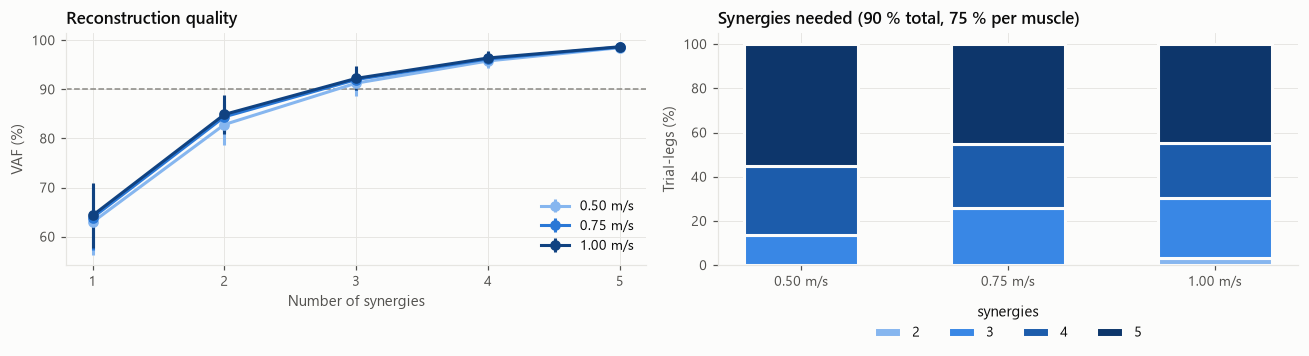

In [4]:
def trial_synergies(s, v, side):
    sel = ((cyc["subject"] == s) & (cyc["speed"] == v) & (cyc["side"] == side)).to_numpy()
    X = np.stack([cur[m][sel].reshape(-1) for m in C.MUSCLES])
    if np.isnan(X).any() or sel.sum() < 20:
        return None
    X = M.prepare_matrix(X)
    r = M.synergies(X, k_max=5)
    return {"subject": s, "speed": v, "side": side, **{f"vaf{k}": r["vaf"][k] for k in r["vaf"]},
            "n_syn": M.n_synergies(r), "n_syn_global": M.n_synergies(r, muscle_threshold=-np.inf), "W3": r["W"][3], "H3": r["H"][3].reshape(3, -1, 101).mean(1),
            "W4": r["W"][4], "H4": r["H"][4].reshape(4, -1, 101).mean(1)}

jobs = cyc[["subject", "speed", "side"]].drop_duplicates().itertuples(index=False)
syn = [r for r in Parallel(n_jobs=-1)(delayed(trial_synergies)(*j) for j in jobs) if r is not None]
SY = pd.DataFrame([{k: v for k, v in r.items() if not k.startswith(("W", "H"))} for r in syn])
print(f"Synergy analysis: {len(SY)} trial-legs from {SY.subject.nunique()} participants")
vaf_tab = SY.groupby("speed")[[f"vaf{k}" for k in range(1, 6)]].mean()
display((100 * vaf_tab).round(1))
print("Synergies needed, global VAF >= 90 % only (% of trial-legs):")
display(pd.crosstab(SY["speed"], SY["n_syn_global"], normalize="index").mul(100).round(0))
print("Synergies needed, global VAF >= 90 % and every muscle >= 75 % (% of trial-legs):")
display(pd.crosstab(SY["speed"], SY["n_syn"], normalize="index").mul(100).round(0))
SY.to_csv(C.TABLES / "emg_synergy_counts.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for s in C.SPEEDS:
    v = SY.loc[SY.speed == s, [f"vaf{k}" for k in range(1, 6)]]
    axes[0].errorbar(np.arange(1, 6), 100 * v.mean(), yerr=100 * v.std(), color=P.SPEED_COLORS[s], marker="o",
                     capsize=0, label=P.SPEED_LABEL[s])
axes[0].axhline(90, color=P.MUTED, ls="--", lw=1)
axes[0].set_xticks(range(1, 6)); axes[0].set_xlabel("Number of synergies"); axes[0].set_ylabel("VAF (%)")
axes[0].set_title("Reconstruction quality"); axes[0].legend()
ct = pd.crosstab(SY["speed"], SY["n_syn"], normalize="index").reindex(C.SPEEDS) * 100
bottom = np.zeros(3)
ramp = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
for k in ct.columns:
    axes[1].bar([P.SPEED_LABEL[s] for s in C.SPEEDS], ct[k], bottom=bottom, color=ramp[k - 1], label=f"{k}", width=0.55,
                edgecolor=P.SURFACE, linewidth=2)
    bottom += ct[k].to_numpy()
axes[1].set_ylabel("Trial-legs (%)"); axes[1].set_title("Synergies needed (90 % total, 75 % per muscle)")
axes[1].legend(title="synergies", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
P.save(fig, "04_synergy_count")
plt.show()

### Are the modules shared across people and speeds?

Four synergies are extracted for every trial-leg (96 % VAF on average), and each
trial's modules are matched to a reference set obtained by clustering all 1.0 m/s modules (k-means on the
synergy vectors). Similarity is the cosine between matched synergy vectors (1 = identical muscle weighting).

,syn1,syn2,syn3,syn4
speed,,,,
0.5,0.986,0.986,0.978,0.902
0.75,0.985,0.987,0.984,0.917
1,0.978,0.987,0.981,0.916


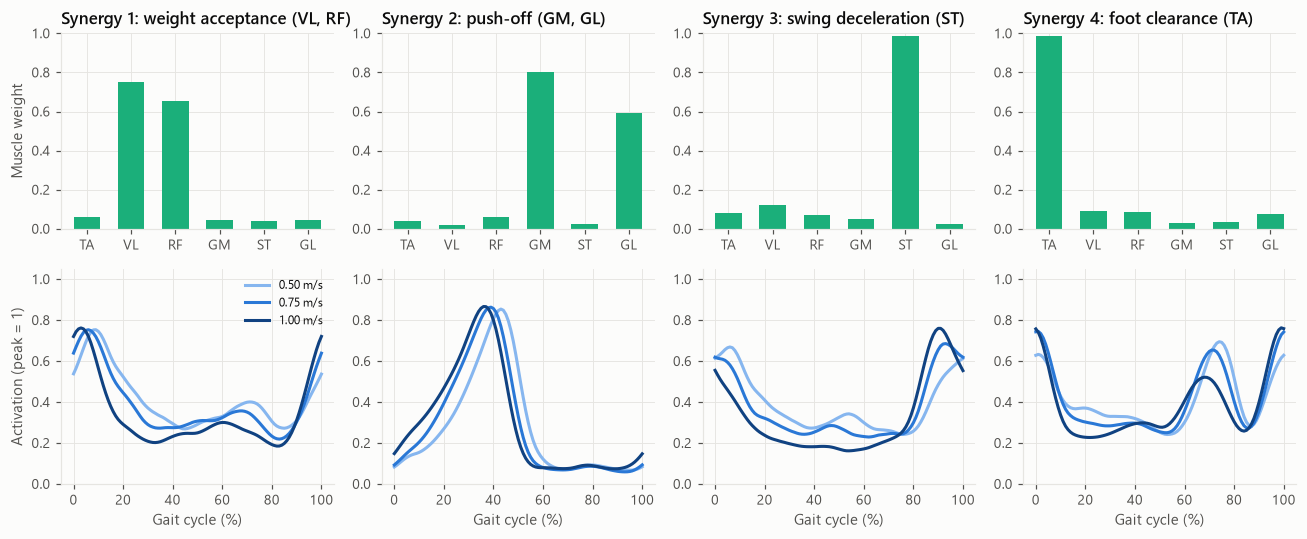

Median cosine similarity of individual synergies to the shared reference: 0.98


In [5]:
from sklearn.cluster import KMeans
K = 4
ref_pool = np.vstack([r["W4"].T for r in syn if r["speed"] == "1"])
km = KMeans(K, n_init=50, random_state=C.SEED).fit(ref_pool)
Wref = (km.cluster_centers_ / np.linalg.norm(km.cluster_centers_, axis=1, keepdims=True)).T
sims, acts = [], {s: [] for s in C.SPEEDS}
for r in syn:
    order, sim = M.match_synergies(Wref, r["W4"])
    sims.append({"subject": r["subject"], "speed": r["speed"], **{f"syn{j + 1}": sim[j] for j in range(K)}})
    acts[r["speed"]].append(r["H4"][order] / r["H4"][order].max(axis=1, keepdims=True))
SIM = pd.DataFrame(sims)
display(SIM.groupby("speed")[[f"syn{j + 1}" for j in range(K)]].median().round(3))
# order synergies by the timing of their activation peak at 1.0 m/s
Hm = {s: np.mean(acts[s], axis=0) for s in C.SPEEDS}
peak_order = np.argsort(Hm["1"].argmax(axis=1))
ROLE = {"VL": "weight acceptance", "RF": "weight acceptance", "GM": "push-off", "GL": "push-off",
        "ST": "swing deceleration", "TA": "foot clearance"}
names = []
for j in peak_order:
    dom = [C.MUSCLES[i] for i in np.argsort(Wref[:, j])[::-1] if Wref[i, j] >= 0.3]
    names.append(f"{ROLE[dom[0]]} ({', '.join(dom)})")
fig, axes = plt.subplots(2, K, figsize=(12, 5), gridspec_kw={"height_ratios": [1, 1.1]})
for c, j in enumerate(peak_order):
    axes[0, c].bar(C.MUSCLES, Wref[:, j], color=P.CAT[2], width=0.6)
    axes[0, c].set_title(f"Synergy {c + 1}: {names[c]}")
    axes[0, c].set_ylim(0, 1)
    for s in C.SPEEDS:
        axes[1, c].plot(x, Hm[s][j], color=P.SPEED_COLORS[s], label=P.SPEED_LABEL[s])
    axes[1, c].set_xlabel("Gait cycle (%)")
    axes[1, c].set_ylim(0, 1.05)
axes[0, 0].set_ylabel("Muscle weight")
axes[1, 0].set_ylabel("Activation (peak = 1)")
axes[1, 0].legend(fontsize=8)
fig.tight_layout()
P.save(fig, "04_synergies")
plt.show()
med_sim = SIM[[f"syn{j + 1}" for j in range(K)]].median().median()
print(f"Median cosine similarity of individual synergies to the shared reference: {med_sim:.2f}")

## 4. Summary

* **Timing is canonical.** All six muscle groups fire at the expected phases of the gait cycle, which also
  confirms the EMG-IMU synchronisation independently of the force plates.
* **Amplitude scales with speed, unevenly.** Per +0.5 m/s, vastus lateralis activation rises about 49 %,
  gastrocnemius medialis 45 % and tibialis anterior 40 %, against 17 to 22 % for semitendinosus, rectus
  femoris and gastrocnemius lateralis. The calf push-off burst moves about 7 % of the cycle earlier, in step
  with the shorter stance. (Peak timing for bimodal muscles such as semitendinosus and tibialis anterior
  switches between bursts and is not interpreted.)
* **Four classic modules, modest compression.** The shared modules are weight acceptance (vastus
  lateralis, rectus femoris), push-off (both gastrocnemius heads), swing deceleration (semitendinosus) and
  foot clearance (tibialis anterior). Under the conventional 90 % total-VAF criterion three synergies suffice
  for 70 to 84 % of trial-legs; adding a 75 % per-muscle criterion typically requires four or five, so with
  six muscles per leg the reduction in dimensionality is limited. Slow walking (0.5 m/s) needs the most
  synergies, i.e. it is the least stereotyped.
* **The modules are stable.** Individual synergies match a shared reference with a median cosine similarity
  of 0.98, at every speed: walking faster changes how strongly the modules are driven, not which muscles
  they combine. This is the property that makes synergy-based monitoring plausible.
* **Limitation.** The 16 Hz envelope limits timing precision to a few percent of the cycle and inflates
  stride-to-stride noise; raw EMG would sharpen both the profiles and the synergy estimates.